# Generador de texto con Redes Neuronales Recurrentes (RNN)
## Conferencias matutinas de la Presidencia de México — septiembre 2026

**Diplomado en Inteligencia Artificial · Módulo 3 · Unidad 5 · Reto 7**

> ⚠️ **Aviso:** proyecto con fines exclusivamente educativos. Todo el texto que produce este notebook es **generado automáticamente por un modelo** y **no representa declaraciones reales** de la presidenta Claudia Sheinbaum Pardo ni de ningún funcionario.

Documentos de referencia: `SPECS.md` (especificaciones) y `DECISIONES.md` (bitácora de decisiones, ADR).

## 0. Definición del problema

### 0.1 Planteamiento
Dado un fragmento de texto inicial (la **semilla**), se quiere que un modelo **continúe la secuencia** generando texto nuevo que imite el estilo discursivo de las conferencias matutinas de la Presidenta: su vocabulario, la estructura de sus frases, su puntuación y sus giros característicos.

Formalmente, es un problema de **modelado de lenguaje**. Se aprende la distribución de probabilidad del siguiente símbolo dado el contexto previo:

$$P(x_t \mid x_1, x_2, \dots, x_{t-1})$$

Con esa distribución se puede generar texto muestreando un símbolo a la vez y realimentándolo como entrada.

### 0.2 Por qué es importante y relevante
- **Es la base de la IA generativa de texto.** Los asistentes conversacionales, el autocompletado y la traducción automática resuelven, en esencia, este mismo problema de predecir el siguiente elemento. Las RNN fueron la arquitectura dominante antes de los Transformers, y entenderlas permite comprender por qué surgieron mecanismos como la atención.
- **El lenguaje es secuencial.** El significado depende del orden y del contexto. Una red densa o convolucional con ventana fija no modela naturalmente dependencias de longitud variable. Una RNN mantiene un **estado oculto** que resume todo lo leído hasta el momento.
- **El caso de estudio es real y en español.** Se usan transcripciones auténticas (~1.6 millones de caracteres) con ruido real (anotaciones del estenógrafo, etiquetas de hablante, tipografía inconsistente). Esto obliga a resolver la **preparación de datos**, que en la práctica es la etapa más costosa de un proyecto de PLN.
- **Permite analizar el estilo.** Un modelo que reproduce el estilo de un orador revela qué patrones lingüísticos lo caracterizan: fórmulas de apertura, conectores frecuentes y temas recurrentes.

### 0.3 Qué se hace en este notebook
1. Analizar y **limpiar** el corpus. Solo se conservan las intervenciones de la Presidenta (ADR-002).
2. Representar el texto **a nivel carácter** (ADR-004).
3. Entrenar y **comparar tres arquitecturas recurrentes** (SimpleRNN, GRU y LSTM) en GPU con PyTorch (ADR-005, ADR-013).
4. **Generar texto** a partir de semillas con distintas temperaturas (ADR-009).
5. **Evaluar** cuantitativa y cualitativamente (ADR-010).

## 1. Configuración

Importaciones, parámetros globales, semillas de reproducibilidad y detección de GPU. Todos los parámetros que controlan el experimento se concentran aquí.

In [1]:
import json
import math
import random
import re
import time
import unicodedata
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

In [2]:
# --- Rutas (relativas a la raíz del proyecto) ---
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RUTA_CORPUS = RAIZ / "Data" / "transcripciones-2026-septiembre.txt"
RUTA_CORPUS_LIMPIO = RAIZ / "Data" / "corpus_limpio.txt"
DIR_MODELOS = RAIZ / "models"
DIR_SALIDAS = RAIZ / "outputs"
DIR_MODELOS.mkdir(exist_ok=True)
DIR_SALIDAS.mkdir(exist_ok=True)

# --- Datos y limpieza (ADR-002, ADR-003) ---
SOLO_PRESIDENTA = True          # D-01: solo intervenciones de la Presidenta
ETIQUETA_PRESIDENTA = "PRESIDENTA DE MÉXICO, CLAUDIA SHEINBAUM PARDO"
QUITAR_ACOTACIONES = True       # D-03: eliminar líneas tipo "—Adelante, Luisa—."
MINUSCULAS = False              # D-04: conservar mayúsculas
MIN_CARACTERES = 3              # D-06: intervenciones con menos caracteres se descartan
MIN_FREQ_CHAR = 5               # caracteres más raros que esto se eliminan
CONFERENCIAS_VALIDACION = 2     # D-10: las 2 últimas conferencias (29 y 30 de sept.)

# --- Secuencias (ADR-008) ---
SEQ_LEN = 100
BATCH_SIZE = 64
PASO_ENTRENAMIENTO = 25         # ventanas solapadas en entrenamiento (más ejemplos)
PASO_VALIDACION = SEQ_LEN + 1   # ventanas sin solapamiento en validación

# --- Entrenamiento (ADR-008) ---
EMB_DIM = 128
DROPOUT_ENTRADA = 0.2
DROPOUT = 0.3
LR = 2e-3
CLIP_NORM = 5.0
EPOCAS_MAX = 50
PACIENCIA = 5
SEED = 42

# --- Generación y evaluación (ADR-009, ADR-010) ---
TEMPERATURAS = [0.2, 0.5, 0.8, 1.0, 1.2]
SEMILLAS_EVALUACION = [
    "Buenos días a todas y a todos. ",
    "El día de hoy vamos a informar sobre ",
    "La transformación de México ",
    "En materia de seguridad, ",
    "Los programas del Bienestar ",
]
LONGITUD_EVALUACION = 400
MODO_INTERACTIVO = False        # True para habilitar la demo con input() (sección 12)

LEYENDA = ("[Texto generado automáticamente por un modelo con fines educativos. "
           "No representa declaraciones reales.]")

In [3]:
def fijar_semillas(semilla=SEED):
    # Fija las semillas de todas las fuentes de aleatoriedad para reproducibilidad.
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.cuda.manual_seed_all(semilla)


fijar_semillas()

DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")
HAY_GPU = DISPOSITIVO.type == "cuda"
UNIDADES = 512 if HAY_GPU else 256   # ADR-011: modelo reducido si no hay GPU

print(f"PyTorch {torch.__version__} | dispositivo: {DISPOSITIVO}")
if HAY_GPU:
    props = torch.cuda.get_device_properties(0)
    print(f"GPU: {props.name} | VRAM: {props.total_memory / 1024**3:.1f} GB | CUDA {torch.version.cuda}")
    torch.backends.cudnn.benchmark = True
else:
    print("⚠️ No se detectó GPU: se usará CPU con 256 unidades por capa.")
print(f"Unidades recurrentes por capa: {UNIDADES}")

PyTorch 2.14.1+cu126 | dispositivo: cuda
GPU: NVIDIA GeForce RTX 3060 Laptop GPU | VRAM: 6.0 GB | CUDA 12.6
Unidades recurrentes por capa: 512


## 2. Carga de datos

El corpus contiene las versiones estenográficas de las 19 conferencias matutinas de septiembre de 2026, concatenadas en un solo archivo de texto UTF-8.

In [4]:
texto_crudo = RUTA_CORPUS.read_text(encoding="utf-8")


def estadisticas(texto):
    # Devuelve estadísticas básicas de un texto.
    return {
        "caracteres": len(texto),
        "palabras": len(texto.split()),
        "líneas": texto.count("\n") + 1,
        "caracteres distintos": len(set(texto)),
    }


stats_crudo = estadisticas(texto_crudo)
pd.DataFrame([stats_crudo], index=["corpus original"])

,caracteres,palabras,líneas,caracteres distintos
corpus original,1626616,268638,15593,106


In [5]:
print(texto_crudo[:1500])

Versión estenográfica. Conferencia de prensa de la presidenta Claudia Sheinbaum Pardo del 02 de septiembre de 2026
Presidencia de la República
02 de septiembre de 2026
---
PRESIDENTA DE MÉXICO, CLAUDIA SHEINBAUM PARDO
Buenos días.
---
PREGUNTA
Buenos días, Presidenta.
---
PRESIDENTA DE MÉXICO, CLAUDIA SHEINBAUM PARDO
¿Cómo están?
---
PREGUNTA
Bien. Gracias.
---
PRESIDENTA DE MÉXICO, CLAUDIA SHEINBAUM PARDO
¿Cómo les gustó el cambio del escenario de “La mañanera”? Fue idea, aquí, de los compañeros.
---
PREGUNTA
Más cercanos.
---
PRESIDENTA DE MÉXICO, CLAUDIA SHEINBAUM PARDO
Están más cerca ustedes también, porque los veía así, hasta… Bueno, buenos días —siéntense, por favor— a todas y a todos.
El día de hoy iniciamos con la Glosa del Informe.
Van a estar viniendo las secretarias, secretarios, directores de instituciones como el IMSS, Pemex, CFE, organismos descentralizados del gobierno, empresas del Estado, para hacer su propio informe, para que conozcan ustedes y quienes nos escuchan c

## 3. Análisis exploratorio

Antes de limpiar hay que entender la estructura del archivo:

- Cada conferencia empieza con un **encabezado de 3 líneas** (`Versión estenográfica...`, `Presidencia de la República` y la fecha) y termina con `—000—`.
- Las intervenciones se separan con `---`. La primera línea de cada bloque es la **etiqueta del hablante** en mayúsculas.

In [6]:
texto_lf = texto_crudo.replace("\r\n", "\n")
lineas = texto_lf.split("\n")

n_conferencias = sum(1 for l in lineas if l.startswith("Versión estenográfica"))
etiquetas = [lineas[i + 1].strip() for i, l in enumerate(lineas[:-1]) if l.strip() == "---"]
conteo_hablantes = Counter(etiquetas)

print(f"Conferencias: {n_conferencias}")
print(f"Intervenciones (bloques '---'): {len(etiquetas)}")
print(f"Hablantes distintos: {len(conteo_hablantes)}\n")
pd.DataFrame(conteo_hablantes.most_common(12), columns=["Hablante", "Intervenciones"])

Conferencias: 19
Intervenciones (bloques '---'): 2507
Hablantes distintos: 117



,Hablante,Intervenciones
0,"PRESIDENTA DE MÉXICO, CLAUDIA SHEINBAUM PARDO",1052
1,PREGUNTA,953
2,"SECRETARIO DE SEGURIDAD Y PROTECCIÓN CIUDADANA, OMAR GARCÍA HARFUCH",54
3,INTERVENCIÓN,29
4,VOZ MUJER,20
5,"GOBERNADOR DE CHIAPAS, EDUARDO RAMÍREZ AGUILAR",18
6,"TITULAR DEL SERVICIO DE ADMINISTRACIÓN TRIBUTARIA (SAT), ANTONIO MARTÍNEZ DAGNINO",13
7,"TITULAR DE LA AGENCIA DE TRANSFORMACIÓN DIGITAL Y TELECOMUNICACIONES, JOSÉ ANTONIO PEÑA MERINO",13
8,"SECRETARIO DE EDUCACIÓN PÚBLICA, MARIO DELGADO CARRILLO",12
9,"COORDINADORA NACIONAL DE PROTECCIÓN CIVIL, LAURA VELÁZQUEZ ALZÚA (ENLACE VIDEOLLAMADA)",12


In [7]:
# Volumen de texto por tipo de hablante
bloques = re.split(r"\n---\n", texto_lf)
volumen = Counter()
for b in bloques:
    partes = b.split("\n", 1)
    if len(partes) == 2:
        etiqueta = partes[0].strip()
        grupo = ("Presidenta" if etiqueta == ETIQUETA_PRESIDENTA
                 else "Prensa (PREGUNTA)" if etiqueta == "PREGUNTA"
                 else "Otros (funcionarios, invitados, videos)")
        volumen[grupo] += len(partes[1])

df_volumen = pd.DataFrame(volumen.items(), columns=["Grupo", "Caracteres"]).sort_values("Caracteres", ascending=False)
df_volumen["%"] = (100 * df_volumen["Caracteres"] / df_volumen["Caracteres"].sum()).round(1)
df_volumen

,Grupo,Caracteres,%
0,"Otros (funcionarios, invitados, videos)",653699,42.9
1,Presidenta,609373,40.0
2,Prensa (PREGUNTA),259291,17.0


In [8]:
# Ejemplos del ruido que se debe limpiar
patrones_ruido = {
    "Anotaciones del estenógrafo": r"\((?:[Ii]naudible|Habla en lengua indígena|INICIA VIDEO|traducción[^)]*)\)",
    "Corchetes editoriales": r"\[[^\]\d][^\]]*\]",
    "Numeración de listas": r"^\[\d+\]",
    "Acotaciones de moderación": r"^\s*[—-][^\n]*[—-]\.?\s*$",
    "Comillas tipográficas": r"[“”‘’´]",
    "Rayas y puntos suspensivos": r"[—–…]",
    "Espacio de ancho cero": "​",
}
filas = []
for nombre, patron in patrones_ruido.items():
    hallazgos = re.findall(patron, texto_lf, flags=re.MULTILINE)
    ejemplo = re.search(patron, texto_lf, flags=re.MULTILINE)
    contexto = texto_lf[max(0, ejemplo.start() - 30): ejemplo.end() + 30].replace("\n", " ⏎ ") if ejemplo else ""
    filas.append({"Tipo de ruido": nombre, "Ocurrencias": len(hallazgos), "Ejemplo (contexto)": contexto})
pd.DataFrame(filas)

,Tipo de ruido,Ocurrencias,Ejemplo (contexto)
0,Anotaciones del estenógrafo,88,"or de mentiras”. ⏎ --- ⏎ PREGUNTA ⏎ (Inaudible) ⏎ --- ⏎ PRESIDENTA DE MÉXICO, CLA"
1,Corchetes editoriales,19,HEINBAUM PARDO ⏎ —Un millón 250 [mil]—. ⏎ --- ⏎ GOBERNADOR DE ZACATECAS
2,Numeración de listas,10,de Búsqueda con 10 acciones: ⏎ [1] Garantizar que todos los repo
3,Acotaciones de moderación,3012,"lica ⏎ 02 de septiembre de 2026 ⏎ --- ⏎ PRESIDENTA DE MÉXICO, CLAUDIA"
4,Comillas tipográficas,2606,"tó el cambio del escenario de “La mañanera”? Fue idea, aquí,"
5,Rayas y puntos suspensivos,2953,"én, porque los veía así, hasta… Bueno, buenos días —siéntense"
6,Espacio de ancho cero,7,primera necesidad decomisados ​​en aduanas en beneficio de ca


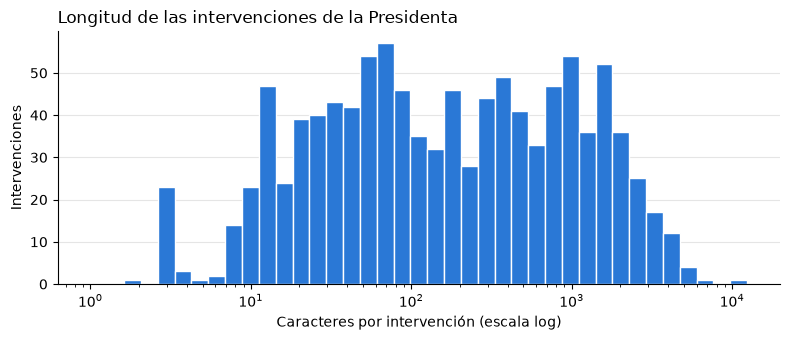

Mediana: 161 caracteres | máximo: 12,410 | total: 609,373


In [9]:
# Distribución de longitudes de las intervenciones de la Presidenta
long_pres = [len(b.split("\n", 1)[1]) for b in bloques
             if b.split("\n", 1)[0].strip() == ETIQUETA_PRESIDENTA and "\n" in b]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(long_pres, bins=np.logspace(0, np.log10(max(long_pres)), 40), color="#2a78d6",
        edgecolor="white", linewidth=1)
ax.set_xscale("log")
ax.set_xlabel("Caracteres por intervención (escala log)")
ax.set_ylabel("Intervenciones")
ax.set_title("Longitud de las intervenciones de la Presidenta", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()
print(f"Mediana: {np.median(long_pres):.0f} caracteres | máximo: {max(long_pres):,} | total: {sum(long_pres):,}")

**Observaciones:**
- La Presidenta aporta cerca del 37 % del texto. El resto mezcla preguntas de prensa, exposiciones técnicas de funcionarios y narraciones de video. Entrenar solo con sus intervenciones da un **estilo homogéneo** (ADR-002).
- Muchas intervenciones son muy cortas (saludos, cesiones de palabra), aunque la mayor parte del volumen está en exposiciones largas.
- El ruido es sistemático y se puede atacar con reglas explícitas (ADR-003).

## 4. Limpieza del corpus

Se implementan los pasos **L1–L14** de `SPECS.md` §4 como funciones pequeñas y puras. Cada paso atiende un tipo de ruido identificado (R1–R12).

In [10]:
# Expresiones regulares de limpieza
RE_ANOTACION = re.compile(
    r"\s*\((?:inaudible|habla en lengua indígena|inicia video|termina video|"
    r"traducción[^)]*|enlace videollamada|videollamada)\)\.?",
    flags=re.IGNORECASE)                                       # L7
RE_SUFIJO_ETIQUETA = re.compile(r"\s*\((?:ENLACE )?VIDEOLLAMADA\)\s*$", re.IGNORECASE)
RE_NUMERACION = re.compile(r"^\[\d+\]\s*", flags=re.MULTILINE)  # L8
RE_CORCHETES = re.compile(r"\[([^\]]*)\]")                      # L9
RE_ACOTACION = re.compile(r"^\s*[—-][^\n]*[—-]\.?\s*$", flags=re.MULTILINE)  # L10
RE_SOLO_ANOTACION = re.compile(r"^\(.*\)\.?$")

MAPA_TIPOGRAFICO = str.maketrans({                              # L11
    "“": '"', "”": '"', "«": '"', "»": '"',
    "‘": "'", "’": "'", "´": "'",
    "—": "-", "–": "-",
})


def normalizar_basico(texto):
    # L1–L3: saltos de línea, Unicode NFC y caracteres invisibles.
    texto = texto.replace("\r\n", "\n").replace("\r", "\n")
    texto = unicodedata.normalize("NFC", texto)
    return texto.replace("​", "").replace("﻿", "").replace(" ", " ")


def dividir_conferencias(texto):
    # L4: separa el archivo en conferencias y descarta encabezados y la marca de cierre.
    trozos = re.split(r"^(?=Versión estenográfica)", texto, flags=re.MULTILINE)
    conferencias = []
    for trozo in trozos:
        if not trozo.startswith("Versión estenográfica"):
            continue
        lineas_conf = trozo.split("\n")[3:]   # 3 líneas de encabezado
        cuerpo = "\n".join(lineas_conf).replace("—000—", "")
        conferencias.append(cuerpo)
    return conferencias


def dividir_intervenciones(conferencia):
    # L5: separa una conferencia en (hablante, texto).
    intervenciones = []
    for bloque in re.split(r"^---\s*$", conferencia, flags=re.MULTILINE):
        lineas_b = [l for l in bloque.strip().split("\n") if l.strip()]
        # Algunos bloques empiezan con una anotación, p. ej. "(INICIA VIDEO)"
        while lineas_b and RE_SOLO_ANOTACION.match(lineas_b[0].strip()):
            lineas_b.pop(0)
        if len(lineas_b) < 2:
            continue
        hablante = RE_SUFIJO_ETIQUETA.sub("", lineas_b[0].strip())
        intervenciones.append((hablante, "\n".join(lineas_b[1:])))
    return intervenciones


def limpiar_texto(texto):
    # L7–L12: limpia el texto de una intervención.
    texto = RE_ANOTACION.sub("", texto)
    texto = RE_NUMERACION.sub("", texto)
    texto = RE_CORCHETES.sub(r"\1", texto)
    if QUITAR_ACOTACIONES:
        texto = RE_ACOTACION.sub("", texto)
    texto = texto.translate(MAPA_TIPOGRAFICO).replace("…", "...")
    if MINUSCULAS:
        texto = texto.lower()
    lineas_limpias = []
    for linea in texto.split("\n"):
        linea = re.sub(r"[ \t]+", " ", linea).strip()
        if re.search(r"\w", linea):          # descarta líneas vacías o de pura puntuación
            lineas_limpias.append(linea)
    return "\n".join(lineas_limpias)


def construir_corpus(texto):
    # Aplica todo el pipeline y devuelve una lista de conferencias limpias (texto).
    conferencias_limpias = []
    for conferencia in dividir_conferencias(normalizar_basico(texto)):
        partes = []
        for hablante, contenido in dividir_intervenciones(conferencia):
            if SOLO_PRESIDENTA and hablante != ETIQUETA_PRESIDENTA:      # L6
                continue
            contenido = limpiar_texto(contenido)
            if len(contenido) >= MIN_CARACTERES:                          # L13
                partes.append(contenido)
        conferencias_limpias.append("\n".join(partes))                  # L14
    return conferencias_limpias

In [11]:
conferencias = construir_corpus(texto_crudo)

# Caracteres raros (< MIN_FREQ_CHAR apariciones): las letras acentuadas se reducen a su
# letra base (ü → u, Ó → O) para no romper palabras; los demás símbolos se eliminan.
def letra_base(c):
    base = unicodedata.normalize("NFKD", c)[0]
    return base if base.isascii() and base.isalpha() else ""


frecuencias = Counter("\n\n".join(conferencias))
raros = {c: n for c, n in frecuencias.items() if n < MIN_FREQ_CHAR}
print("Caracteres raros:", {f"{c!r} ({n})": letra_base(c) or "(eliminado)" for c, n in raros.items()} or "ninguno")
if raros:
    tabla_raros = str.maketrans({c: letra_base(c) for c in raros})
    conferencias = [c.translate(tabla_raros) for c in conferencias]

corpus_limpio = "\n\n".join(conferencias)     # L14: conferencias separadas por línea en blanco
RUTA_CORPUS_LIMPIO.write_text(corpus_limpio, encoding="utf-8")
print(f"Conferencias procesadas: {len(conferencias)}")
print(f"Corpus limpio guardado en {RUTA_CORPUS_LIMPIO.relative_to(RAIZ)}")

Caracteres raros: {"'%' (2)": '(eliminado)', "'ü' (3)": 'u', "'Ó' (2)": 'O', "'Í' (1)": 'I', "'*' (1)": '(eliminado)'}


Conferencias procesadas: 19
Corpus limpio guardado en Data\corpus_limpio.txt


### 4.1 Verificación de la limpieza

In [12]:
pd.DataFrame([stats_crudo, estadisticas(corpus_limpio)], index=["original", "limpio"])

,caracteres,palabras,líneas,caracteres distintos
original,1626616,268638,15593,106
limpio,591295,100107,4174,84


In [13]:
# Verificaciones automáticas (SPECS §4.2)
assert "---" not in corpus_limpio, "Quedan separadores ---"
assert "—000—" not in corpus_limpio, "Quedan marcas de fin de conferencia"
assert "Versión estenográfica" not in corpus_limpio, "Quedan encabezados"
assert not re.search(r"\(inaudible\)", corpus_limpio, re.IGNORECASE), "Quedan anotaciones (Inaudible)"
assert not re.search(r"[“”‘’—–…​]", corpus_limpio), "Quedan variantes tipográficas"
assert ETIQUETA_PRESIDENTA not in corpus_limpio, "Quedan etiquetas de hablante"
etiquetas_residuales = re.findall(r"^[A-ZÁÉÍÓÚÑ ()]{4,}, [A-ZÁÉÍÓÚÑ ]{4,}$", corpus_limpio, flags=re.MULTILINE)
assert not etiquetas_residuales, f"Posibles etiquetas residuales: {etiquetas_residuales[:3]}"
assert not re.search(r"^PREGUNTA$", corpus_limpio, flags=re.MULTILINE), "Quedan etiquetas PREGUNTA"
print("✅ Todas las verificaciones de limpieza pasaron.")

✅ Todas las verificaciones de limpieza pasaron.


In [14]:
# Vocabulario final de caracteres con sus frecuencias
freq_final = Counter(corpus_limpio)
df_chars = pd.DataFrame(freq_final.most_common(), columns=["Carácter", "Frecuencia"])
df_chars["Carácter"] = df_chars["Carácter"].map(lambda c: {"\n": "⏎ (salto)", " ": "␣ (espacio)"}.get(c, c))
print(f"Vocabulario de caracteres: {len(freq_final)} símbolos (original: {stats_crudo['caracteres distintos']})")
print(" ".join(f"{c}:{n}" for c, n in zip(df_chars["Carácter"], df_chars["Frecuencia"])))

Vocabulario de caracteres: 84 símbolos (original: 106)
␣ (espacio):95951 e:62686 a:51453 o:40760 s:35080 n:34887 r:27826 i:27535 l:22001 d:21588 t:20647 u:19324 c:19012 m:12837 p:11621 ,:9519 .:6733 q:5825 b:5201 y:4824 v:4718 g:4262 h:4212 ⏎ (salto):4173 ó:3314 í:3009 f:2424 é:2060 E:2004 á:1941 j:1691 P:1328 ":1252 z:1106 x:1076 S:1040 M:1017 Y:1001 C:947 A:894 -:704 ñ:628 N:624 I:615 G:578 ú:574 B:571 L:557 2:522 ¿:484 ?:482 0:471 ::456 T:453 ;:393 1:390 D:372 R:355 F:326 U:323 H:308 O:271 V:211 5:210 Q:183 3:181 4:173 6:163 8:148 J:147 7:143 9:133 ':99 Z:65 ¡:39 !:39 X:31 k:24 Á:20 É:14 K:12 º:11 w:8 W:5


In [15]:
# Muestras aleatorias del corpus limpio para revisión visual
rng = random.Random(SEED)
for i in range(5):
    inicio = rng.randrange(0, len(corpus_limpio) - 300)
    print(f"--- Muestra {i + 1} (posición {inicio:,}) ---")
    print(corpus_limpio[inicio:inicio + 300], "\n")

--- Muestra 1 (posición 116,739) ---
ilia". Bueno, ya ni en su propia teoría, porque si un padre no fue a la universidad y el hijo logra ir a la universidad, pues el objetivo es que pueda haber mayor ingreso, porque tienen más educación.
Entonces, ¿qué, eso está mal? Entonces, ¿mejor que los hijos no vayan a estudiar para que no vaya a 

--- Muestra 2 (posición 26,225) ---
a la Constitución con igualdad sustantiva fue por unanimidad, todos y todas estuvieron de acuerdo.
Entonces, hay temas que puede haber unanimidad y otros no, pero no pasa nada. Esa es la democracia.
Si todos pensáramos igual, pues entonces sí habría autoritarismo; o si se castigara a quien piensa di 

--- Muestra 3 (posición 288,389) ---
s 8 columnas de todos los días.
Pasa algo muy importante en el país: eso no sale.
¡Ah!, pero tergiversar la realidad de la manera que cuadre con su propaganda: eso sí
Es más, ahorita le voy a pedir a Octavio que aclare el tema de lo de su declaración patrimonial, porque buscan tergiv

## 5. Vocabulario y preparación de secuencias

- Cada carácter se mapea a un índice entero (`char2idx`).
- El modelo recibe ventanas de `SEQ_LEN = 100` caracteres y debe predecir, **en cada posición**, el carácter siguiente. Es un esquema *many-to-many*: la salida es la misma secuencia desplazada una posición.

```
entrada : "Buenos día"
objetivo: "uenos días"
```

- **División entrenamiento/validación por conferencias (ADR-007):** las 2 últimas conferencias (29 y 30 de septiembre) se reservan para validación. Así se evalúa la capacidad de generalizar a días no vistos, sin que fragmentos casi idénticos queden en ambos conjuntos.
- En entrenamiento las ventanas se solapan (paso de 25 caracteres) para obtener más ejemplos. En validación no se solapan.

In [16]:
vocabulario = sorted(set(corpus_limpio))
char2idx = {c: i for i, c in enumerate(vocabulario)}
idx2char = np.array(vocabulario)
V = len(vocabulario)

with open(DIR_MODELOS / "vocabulario.json", "w", encoding="utf-8") as f:
    json.dump({"vocabulario": vocabulario}, f, ensure_ascii=False, indent=1)


def codificar(texto):
    return np.array([char2idx[c] for c in texto if c in char2idx], dtype=np.int64)


def decodificar(indices):
    return "".join(idx2char[indices])


texto_entrenamiento = "\n\n".join(conferencias[:-CONFERENCIAS_VALIDACION])
texto_validacion = "\n\n".join(conferencias[-CONFERENCIAS_VALIDACION:])
datos_entrenamiento = codificar(texto_entrenamiento)
datos_validacion = codificar(texto_validacion)

print(f"Tamaño del vocabulario V = {V}")
print(f"Entrenamiento: {len(datos_entrenamiento):,} caracteres ({len(conferencias) - CONFERENCIAS_VALIDACION} conferencias)")
print(f"Validación:    {len(datos_validacion):,} caracteres ({CONFERENCIAS_VALIDACION} conferencias)"
      f" → {100 * len(datos_validacion) / (len(datos_entrenamiento) + len(datos_validacion)):.1f} %")
print("Ejemplo de codificación:", codificar("Buenos días"), "→", repr(decodificar(codificar("Buenos días"))))

Tamaño del vocabulario V = 84
Entrenamiento: 544,319 caracteres (17 conferencias)
Validación:    46,974 caracteres (2 conferencias) → 7.9 %
Ejemplo de codificación: [22 67 51 60 61 65  1 50 80 47 65] → 'Buenos días'


In [17]:
class DatasetCaracteres(Dataset):
    # Ventanas (entrada, objetivo) de longitud seq_len sobre una secuencia de índices.

    def __init__(self, datos, seq_len, paso):
        self.datos = torch.from_numpy(datos)
        self.seq_len = seq_len
        self.inicios = range(0, len(datos) - seq_len - 1, paso)

    def __len__(self):
        return len(self.inicios)

    def __getitem__(self, i):
        inicio = self.inicios[i]
        trozo = self.datos[inicio: inicio + self.seq_len + 1]
        return trozo[:-1], trozo[1:]


ds_entrenamiento = DatasetCaracteres(datos_entrenamiento, SEQ_LEN, PASO_ENTRENAMIENTO)
ds_validacion = DatasetCaracteres(datos_validacion, SEQ_LEN, PASO_VALIDACION)

generador_dl = torch.Generator().manual_seed(SEED)
dl_entrenamiento = DataLoader(ds_entrenamiento, batch_size=BATCH_SIZE, shuffle=True,
                              drop_last=True, pin_memory=HAY_GPU, generator=generador_dl)
dl_validacion = DataLoader(ds_validacion, batch_size=BATCH_SIZE, shuffle=False,
                           drop_last=False, pin_memory=HAY_GPU)

x, y = ds_entrenamiento[0]
print(f"Ventanas de entrenamiento: {len(ds_entrenamiento):,} → {len(dl_entrenamiento)} batches por época")
print(f"Ventanas de validación:    {len(ds_validacion):,} → {len(dl_validacion)} batches")
print(f"\nentrada : {decodificar(x[:40].numpy())!r}")
print(f"objetivo: {decodificar(y[:40].numpy())!r}")

Ventanas de entrenamiento: 21,769 → 340 batches por época
Ventanas de validación:    465 → 8 batches

entrada : 'Buenos días.\n¿Cómo están?\n¿Cómo les gust'
objetivo: 'uenos días.\n¿Cómo están?\n¿Cómo les gustó'


## 6. Fundamentos teóricos y justificación del diseño

### 6.1 Redes neuronales recurrentes (RNN)
Una RNN procesa la secuencia elemento por elemento y mantiene un **estado oculto** $h_t$ que resume el contexto visto hasta el paso $t$:

$$h_t = \tanh(W_{xh}\,x_t + W_{hh}\,h_{t-1} + b_h), \qquad \hat{y}_t = \mathrm{softmax}(W_{hy}\,h_t + b_y)$$

Los mismos pesos se comparten en todos los pasos de tiempo. Por eso la red procesa secuencias de cualquier longitud con un número fijo de parámetros.

### 6.2 El problema del gradiente que se desvanece
Al entrenar con *backpropagation through time*, el gradiente respecto de pasos lejanos incluye productos repetidos de $W_{hh}$ y de la derivada de $\tanh$ (que es ≤ 1):

$$\frac{\partial h_t}{\partial h_k} = \prod_{i=k+1}^{t} \mathrm{diag}\big(1 - h_i^2\big)\, W_{hh}$$

Si los valores singulares son < 1, el gradiente **decae exponencialmente**: la red simple "olvida" lo que ocurrió más de unos pocos pasos atrás. Si son > 1, el gradiente **explota**. Este segundo caso se mitiga con *gradient clipping* (`clip_grad_norm_ = 5.0`).

### 6.3 LSTM (Long Short-Term Memory)
La LSTM agrega un **estado de celda** $c_t$ que se actualiza de forma aditiva y se controla con tres compuertas:

$$
\begin{aligned}
f_t &= \sigma(W_f [h_{t-1}, x_t] + b_f) && \text{compuerta de olvido}\\
i_t &= \sigma(W_i [h_{t-1}, x_t] + b_i) && \text{compuerta de entrada}\\
\tilde{c}_t &= \tanh(W_c [h_{t-1}, x_t] + b_c) && \text{candidato}\\
c_t &= f_t \odot c_{t-1} + i_t \odot \tilde{c}_t && \text{actualización aditiva}\\
o_t &= \sigma(W_o [h_{t-1}, x_t] + b_o), \quad h_t = o_t \odot \tanh(c_t) && \text{compuerta de salida}
\end{aligned}
$$

Como $c_t$ depende de $c_{t-1}$ de forma **aditiva** (modulada por $f_t$), el gradiente fluye sin multiplicarse repetidamente por $W_{hh}$. Así la red recuerda dependencias largas: cerrar un `¿…?` abierto, mantener la concordancia de género y número, o terminar una enumeración.

### 6.4 GRU (Gated Recurrent Unit)
La GRU simplifica la LSTM a dos compuertas (actualización $z_t$ y reinicio $r_t$) y fusiona celda y estado oculto:

$$h_t = (1 - z_t) \odot h_{t-1} + z_t \odot \tanh\big(W [r_t \odot h_{t-1}, x_t]\big)$$

Tiene ~25 % menos parámetros que una LSTM del mismo tamaño y suele rendir de forma similar.

### 6.5 ¿Por qué nivel carácter? (ADR-004)
| Criterio | Carácter | Palabra |
|---|---|---|
| Vocabulario | ~80 símbolos | ~26,600 palabras |
| Ejemplos por clase | miles | la mayoría 1–2 apariciones |
| Palabras fuera de vocabulario | imposibles | frecuentes |
| Morfología del español | se aprende | cada forma es una clase aparte |

Con ~100 mil palabras de la Presidenta, un modelo por palabras tendría muy pocos ejemplos por clase. El nivel carácter es la opción teóricamente adecuada.

### 6.6 ¿Por qué RNN y no CNN?
Las **redes convolucionales (CNN)** son ideales para datos con estructura espacial local e invariancia a traslación, como las imágenes. Sus filtros de tamaño fijo capturan patrones locales, y para ampliar el contexto hay que apilar muchas capas o usar dilataciones. Además, una CNN estándar no tiene una noción natural de "estado" que se arrastre en el tiempo.

El texto es **secuencial y causal**: cada símbolo depende de todo lo anterior, con dependencias de longitud variable. Una RNN modela exactamente esto con su estado oculto recurrente. Además, la generación es naturalmente autoregresiva: se produce un símbolo, se realimenta y se actualiza el estado.

### 6.7 Arquitecturas que se comparan (ADR-005)
| Modelo | Rol | Capas | Unidades |
|---|---|---|---|
| SimpleRNN | Línea base: ilustra el gradiente que se desvanece | 1 | 256 |
| GRU | Alternativa con compuertas, más ligera | 2 | 512 |
| **LSTM** | **Modelo principal** | 2 | 512 |

Una LSTM **bidireccional** no aplica: para generar texto el modelo no puede ver el futuro.

## 7. Definición de los modelos

Una sola clase parametrizable sirve para los tres tipos de celda. Así se garantiza que la comparación sea justa: mismo embedding, mismo dropout y misma capa de salida.

```
 índices (batch, 100)
        │
 ┌──────▼──────┐
 │ Embedding   │  V → 128
 └──────┬──────┘
   Dropout 0.2
 ┌──────▼──────┐
 │ RNN/GRU/LSTM│  capa 1 (512)
 │   capa 2    │  (dropout 0.3 entre capas)
 └──────┬──────┘
   Dropout 0.3
 ┌──────▼──────┐
 │ Linear      │  512 → V   (logits)
 └──────┬──────┘
 logits (batch, 100, V)  +  estado oculto (h, c)
```

In [18]:
CELDAS = {"rnn": nn.RNN, "gru": nn.GRU, "lstm": nn.LSTM}


class ModeloCaracteres(nn.Module):
    # Modelo de lenguaje a nivel carácter con celda recurrente configurable.

    def __init__(self, tipo_celda, vocab_size, emb_dim, unidades, capas, dropout_entrada, dropout):
        super().__init__()
        self.tipo_celda = tipo_celda
        self.embedding = nn.Embedding(vocab_size, emb_dim)
        self.dropout_entrada = nn.Dropout(dropout_entrada)
        argumentos = dict(input_size=emb_dim, hidden_size=unidades, num_layers=capas,
                          batch_first=True, dropout=dropout if capas > 1 else 0.0)
        if tipo_celda == "rnn":
            argumentos["nonlinearity"] = "tanh"
        self.rnn = CELDAS[tipo_celda](**argumentos)
        self.dropout_salida = nn.Dropout(dropout)
        self.salida = nn.Linear(unidades, vocab_size)

    def forward(self, x, estado=None):
        # x: (batch, seq) → logits (batch, seq, V) y nuevo estado oculto.
        z = self.dropout_entrada(self.embedding(x))
        z, estado = self.rnn(z, estado)
        return self.salida(self.dropout_salida(z)), estado


CONFIG_MODELOS = {
    "simplernn": dict(tipo_celda="rnn", unidades=256, capas=1),
    "gru": dict(tipo_celda="gru", unidades=UNIDADES, capas=2),
    "lstm": dict(tipo_celda="lstm", unidades=UNIDADES, capas=2),
}


def crear_modelo(nombre):
    cfg = CONFIG_MODELOS[nombre]
    return ModeloCaracteres(vocab_size=V, emb_dim=EMB_DIM, dropout_entrada=DROPOUT_ENTRADA,
                            dropout=DROPOUT, **cfg).to(DISPOSITIVO)


def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)

In [19]:
# Resumen de arquitectura y parámetros por capa
filas = []
for nombre in CONFIG_MODELOS:
    m = crear_modelo(nombre)
    for capa, modulo in m.named_children():
        n = sum(p.numel() for p in modulo.parameters())
        filas.append({"Modelo": nombre, "Capa": capa, "Módulo": str(modulo), "Parámetros": n})
    filas.append({"Modelo": nombre, "Capa": "TOTAL", "Módulo": "", "Parámetros": contar_parametros(m)})
    del m

df_arquitectura = pd.DataFrame(filas)
df_arquitectura["Parámetros"] = df_arquitectura["Parámetros"].map("{:,}".format)
df_arquitectura

,Modelo,Capa,Módulo,Parámetros
0,simplernn,embedding,"Embedding(84, 128)","10,752"
1,simplernn,dropout_entrada,"Dropout(p=0.2, inplace=False)",0
2,simplernn,rnn,"RNN(128, 256, batch_first=True)","98,816"
3,simplernn,dropout_salida,"Dropout(p=0.3, inplace=False)",0
4,simplernn,salida,"Linear(in_features=256, out_features=84, bias=True)","21,588"
5,simplernn,TOTAL,,"131,156"
6,gru,embedding,"Embedding(84, 128)","10,752"
7,gru,dropout_entrada,"Dropout(p=0.2, inplace=False)",0
8,gru,rnn,"GRU(128, 512, num_layers=2, batch_first=True, dropout=0.3)","2,562,048"
9,gru,dropout_salida,"Dropout(p=0.3, inplace=False)",0


### 7.1 Generación de texto (muestreo con temperatura)

La función `generar_texto` se define aquí porque también se usa durante el entrenamiento, para ver cómo progresa el modelo época a época. Su funcionamiento se analiza en la sección 10.

1. **Calentamiento:** la semilla completa pasa por la red para construir el estado oculto.
2. **Muestreo autoregresivo:** en cada paso, los logits se dividen entre la **temperatura** $T$. Se aplica softmax y se muestrea un carácter, que se realimenta junto con el estado.

$$p_i = \frac{\exp(z_i / T)}{\sum_j \exp(z_j / T)}$$

Con $T < 1$ la distribución se vuelve más "picuda" (conservadora). Con $T > 1$ se aplana (más creativa y con más errores).

In [20]:
@torch.no_grad()
def generar_texto(modelo, semilla, longitud=500, temperatura=0.7, top_k=None, con_leyenda=False):
    # Genera `longitud` caracteres a partir de `semilla`. Devuelve semilla + texto generado.
    modelo.eval()
    faltantes = sorted({c for c in semilla if c not in char2idx})
    if faltantes:
        print(f"⚠️ Caracteres fuera del vocabulario ignorados: {faltantes}")
    indices = codificar(semilla)
    if len(indices) == 0:
        indices = np.array([char2idx["\n"]])
    entrada = torch.from_numpy(indices).unsqueeze(0).to(DISPOSITIVO)

    logits, estado = modelo(entrada, None)          # calentamiento con la semilla
    logits = logits[:, -1, :]
    generados = []
    for _ in range(longitud):
        logits = logits / temperatura
        if top_k is not None:
            umbral = torch.topk(logits, top_k).values[:, -1, None]
            logits = logits.masked_fill(logits < umbral, float("-inf"))
        probabilidades = torch.softmax(logits, dim=-1)
        siguiente = torch.multinomial(probabilidades, num_samples=1)
        generados.append(siguiente.item())
        logits, estado = modelo(siguiente, estado)
        logits = logits[:, -1, :]

    texto = semilla + decodificar(np.array(generados))
    return f"{LEYENDA}\n{texto}" if con_leyenda else texto

## 8. Entrenamiento

El ciclo de entrenamiento se escribe de forma explícita para que cada paso sea visible:

1. **forward:** el modelo produce logits para cada posición.
2. **pérdida:** entropía cruzada entre los logits y el carácter real siguiente.
3. **backward:** se calculan los gradientes.
4. **gradient clipping:** la norma del gradiente se limita a 5.0 para evitar que explote.
5. **paso del optimizador:** Adam actualiza los pesos.

Además se usan:
- `ReduceLROnPlateau`, que reduce a la mitad la tasa de aprendizaje si `val_loss` no mejora en 2 épocas;
- **early stopping** con paciencia de 5 épocas;
- **checkpoint** del mejor modelo según `val_loss`.

Los tres modelos usan exactamente la misma configuración (D-08).

In [21]:
criterio = nn.CrossEntropyLoss()


@torch.no_grad()
def evaluar(modelo, dataloader):
    # Devuelve (pérdida media, exactitud) sobre un dataloader.
    modelo.eval()
    perdida_total, aciertos, total = 0.0, 0, 0
    for x, y in dataloader:
        x, y = x.to(DISPOSITIVO, non_blocking=True), y.to(DISPOSITIVO, non_blocking=True)
        logits, _ = modelo(x)
        perdida_total += criterio(logits.reshape(-1, V), y.reshape(-1)).item() * y.numel()
        aciertos += (logits.argmax(-1) == y).sum().item()
        total += y.numel()
    return perdida_total / total, aciertos / total


def entrenar_modelo(nombre, epocas_muestra=(1, 5), semilla_muestra=SEMILLAS_EVALUACION[0]):
    # Entrena un modelo con early stopping y checkpoint. Devuelve (modelo, historial, muestras).
    fijar_semillas()
    modelo = crear_modelo(nombre)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=LR)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizador, factor=0.5, patience=2, min_lr=1e-5)
    ruta_checkpoint = DIR_MODELOS / f"{nombre}_mejor.pt"

    historial, muestras = [], {}
    mejor_val, epocas_sin_mejora, mejor_epoca = float("inf"), 0, 0
    print(f"\n=== Entrenando {nombre.upper()} ({contar_parametros(modelo):,} parámetros) ===")

    for epoca in range(1, EPOCAS_MAX + 1):
        inicio = time.time()
        modelo.train()
        perdida_acum, n_tokens = 0.0, 0
        for x, y in dl_entrenamiento:
            x, y = x.to(DISPOSITIVO, non_blocking=True), y.to(DISPOSITIVO, non_blocking=True)
            optimizador.zero_grad(set_to_none=True)
            logits, _ = modelo(x)                                         # 1. forward
            perdida = criterio(logits.reshape(-1, V), y.reshape(-1))      # 2. pérdida
            perdida.backward()                                            # 3. backward
            nn.utils.clip_grad_norm_(modelo.parameters(), CLIP_NORM)      # 4. clipping
            optimizador.step()                                            # 5. optimizador
            perdida_acum += perdida.item() * y.numel()
            n_tokens += y.numel()

        perdida_entrenamiento = perdida_acum / n_tokens
        perdida_val, exactitud_val = evaluar(modelo, dl_validacion)
        lr_actual = optimizador.param_groups[0]["lr"]
        scheduler.step(perdida_val)
        duracion = time.time() - inicio
        historial.append({"época": epoca, "loss": perdida_entrenamiento, "val_loss": perdida_val,
                          "val_accuracy": exactitud_val, "lr": lr_actual, "segundos": duracion})

        marca = ""
        if perdida_val < mejor_val:
            mejor_val, mejor_epoca, epocas_sin_mejora = perdida_val, epoca, 0
            torch.save(modelo.state_dict(), ruta_checkpoint)
            marca = " ✓ checkpoint"
        else:
            epocas_sin_mejora += 1
        print(f"época {epoca:2d} | loss {perdida_entrenamiento:.4f} | val_loss {perdida_val:.4f} "
              f"| val_acc {exactitud_val:.3f} | lr {lr_actual:.1e} | {duracion:4.1f}s{marca}")

        if epoca in epocas_muestra:
            fijar_semillas()
            muestras[f"época {epoca}"] = generar_texto(modelo, semilla_muestra, 250, 0.5)
        if epocas_sin_mejora >= PACIENCIA:
            print(f"Early stopping: sin mejora en {PACIENCIA} épocas.")
            break

    modelo.load_state_dict(torch.load(ruta_checkpoint, map_location=DISPOSITIVO))
    fijar_semillas()
    muestras[f"mejor (época {mejor_epoca})"] = generar_texto(modelo, semilla_muestra, 250, 0.5)
    print(f"Mejor val_loss: {mejor_val:.4f} en la época {mejor_epoca} → {ruta_checkpoint.relative_to(RAIZ)}")
    return modelo, pd.DataFrame(historial), muestras

In [22]:
modelos, historiales, muestras_progreso, tiempos = {}, {}, {}, {}
for nombre in ["simplernn", "gru", "lstm"]:
    t0 = time.time()
    modelos[nombre], historiales[nombre], muestras_progreso[nombre] = entrenar_modelo(nombre)
    tiempos[nombre] = time.time() - t0
    if HAY_GPU:
        torch.cuda.empty_cache()

print("\nTiempo total de entrenamiento: "
      f"{sum(tiempos.values()) / 60:.1f} min ({', '.join(f'{k}: {v / 60:.1f} min' for k, v in tiempos.items())})")


=== Entrenando SIMPLERNN (131,156 parámetros) ===


época  1 | loss 1.9951 | val_loss 1.6677 | val_acc 0.509 | lr 2.0e-03 |  1.6s ✓ checkpoint


época  2 | loss 1.6668 | val_loss 1.5521 | val_acc 0.544 | lr 2.0e-03 |  1.3s ✓ checkpoint


época  3 | loss 1.5857 | val_loss 1.5005 | val_acc 0.560 | lr 2.0e-03 |  1.3s ✓ checkpoint


época  4 | loss 1.5440 | val_loss 1.4757 | val_acc 0.566 | lr 2.0e-03 |  1.3s ✓ checkpoint


época  5 | loss 1.5204 | val_loss 1.4636 | val_acc 0.568 | lr 2.0e-03 |  1.3s ✓ checkpoint


... (71 outputs left out)

época 10 | loss 0.9181 | val_loss 1.1956 | val_acc 0.655 | lr 2.0e-03 |  9.1s


época 11 | loss 0.8775 | val_loss 1.1987 | val_acc 0.657 | lr 1.0e-03 |  9.0s


época 12 | loss 0.8581 | val_loss 1.2067 | val_acc 0.657 | lr 1.0e-03 |  9.0s
Early stopping: sin mejora en 5 épocas.


Mejor val_loss: 1.1799 en la época 7 → models\lstm_mejor.pt

Tiempo total de entrenamiento: 4.9 min (simplernn: 1.2 min, gru: 1.9 min, lstm: 1.8 min)


## 9. Comparación de modelos

Métricas intrínsecas sobre el conjunto de validación (conferencias no vistas):

- **Perplejidad** $= e^{\text{val\_loss}}$: número efectivo de caracteres entre los que el modelo "duda" en cada paso.
- **Bits por carácter (BPC)** $= \text{val\_loss} / \ln 2$: cuántos bits necesita el modelo, en promedio, para codificar cada carácter. Menos es mejor. Umbral de aceptación: ≤ 1.6.
- **Exactitud:** porcentaje de veces que el carácter más probable es el correcto.

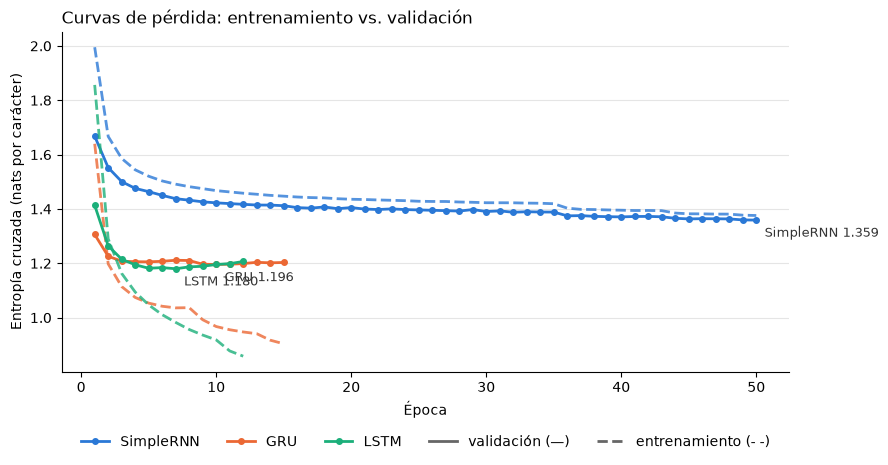

In [23]:
COLORES = {"simplernn": "#2a78d6", "gru": "#eb6834", "lstm": "#1baf7a"}   # orden categorical fijo
NOMBRES = {"simplernn": "SimpleRNN", "gru": "GRU", "lstm": "LSTM"}

fig, ax = plt.subplots(figsize=(9, 4.8))
for nombre, h in historiales.items():
    ax.plot(h["época"], h["loss"], color=COLORES[nombre], linewidth=2, linestyle="--", alpha=0.8)
    ax.plot(h["época"], h["val_loss"], color=COLORES[nombre], linewidth=2,
            marker="o", markersize=4, label=f"{NOMBRES[nombre]}")
    mejor = h.loc[h["val_loss"].idxmin()]
    ax.annotate(f"{NOMBRES[nombre]} {mejor['val_loss']:.3f}", (mejor["época"], mejor["val_loss"]),
                xytext=(6, -12), textcoords="offset points", fontsize=9, color="#333333")

ax.plot([], [], color="#666666", linewidth=2, label="validación (—)")
ax.plot([], [], color="#666666", linewidth=2, linestyle="--", label="entrenamiento (- -)")
ax.set_xlabel("Época")
ax.set_ylabel("Entropía cruzada (nats por carácter)")
ax.set_title("Curvas de pérdida: entrenamiento vs. validación", loc="left")
ax.legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.15))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(DIR_SALIDAS / "curvas_perdida.png", dpi=150, bbox_inches="tight")
plt.show()

In [24]:
filas = []
for nombre, h in historiales.items():
    mejor = h.loc[h["val_loss"].idxmin()]
    filas.append({
        "Modelo": NOMBRES[nombre],
        "Parámetros": contar_parametros(modelos[nombre]),
        "Mejor época": int(mejor["época"]),
        "Épocas entrenadas": len(h),
        "loss (train)": round(mejor["loss"], 4),
        "val_loss": round(mejor["val_loss"], 4),
        "Perplejidad": round(math.exp(mejor["val_loss"]), 3),
        "BPC": round(mejor["val_loss"] / math.log(2), 3),
        "Exactitud val": round(mejor["val_accuracy"], 4),
        "Brecha (val - train)": round(mejor["val_loss"] - mejor["loss"], 4),
        "Tiempo (min)": round(tiempos[nombre] / 60, 2),
        "s/época": round(h["segundos"].mean(), 1),
    })
df_metricas = pd.DataFrame(filas).set_index("Modelo")
df_metricas.to_csv(DIR_SALIDAS / "metricas_modelos.csv", encoding="utf-8")

NOMBRE_MEJOR = min(historiales, key=lambda n: historiales[n]["val_loss"].min())
modelo_final = modelos[NOMBRE_MEJOR]
print(f"🏆 Modelo seleccionado (menor val_loss): {NOMBRES[NOMBRE_MEJOR]}")
df_metricas

🏆 Modelo seleccionado (menor val_loss): LSTM


,Parámetros,Mejor época,Épocas entrenadas,loss (train),val_loss,Perplejidad,BPC,Exactitud val,Brecha (val - train),Tiempo (min),s/época
Modelo,,,,,,,,,,,
SimpleRNN,131156,50,50,1.3759,1.3589,3.892,1.961,0.6019,-0.0169,1.15,1.3
GRU,2615892,10,15,0.9672,1.1957,3.306,1.725,0.6509,0.2285,1.89,7.5
LSTM,3469908,7,12,0.9825,1.1799,3.254,1.702,0.6529,0.1974,1.81,9.0


### 9.1 Ajuste acotado de hiperparámetros (SPECS §6.6)

Las curvas muestran que la LSTM y la GRU alcanzan su mejor `val_loss` en pocas épocas. Después, la pérdida de entrenamiento sigue bajando mientras la de validación sube: es **sobreajuste**. Para comprobar si más regularización o un modelo más pequeño mejoran la generalización, se probaron cuatro variantes de la LSTM, cambiando un factor a la vez.

Resultados obtenidos en la ejecución de referencia (RTX 3060, misma semilla y mismos datos):

| Variante LSTM | Dropout | Unidades | Mejor época | loss (train) | val_loss | BPC |
|---|---|---|---|---|---|---|
| Base (seleccionada) | 0.3 | 512 | 6 | 1.013 | **1.175** | **1.695** |
| Más regularización | 0.5 | 512 | 10 | 1.031 | 1.175 | 1.695 |
| Modelo más pequeño | 0.3 | 256 | 28 | 0.997 | 1.179 | 1.701 |
| Ambos | 0.5 | 256 | 37 | 1.098 | 1.190 | 1.716 |

**Interpretación:** todas las variantes convergen al mismo piso de `val_loss` ≈ 1.17–1.19. Más dropout solo retrasa el sobreajuste y un modelo más pequeño solo tarda más en llegar al mismo punto. Por lo tanto, el límite **no es la capacidad ni la regularización, sino los datos**: un corpus de ~540 mil caracteres de entrenamiento y unas conferencias de validación con temas que no aparecen en entrenamiento. Se conserva la configuración base.

Para reproducir el experimento (≈ 10 min en GPU), cambia `EJECUTAR_AJUSTE = True` en la celda siguiente.

In [25]:
EJECUTAR_AJUSTE = False

if EJECUTAR_AJUSTE:
    dropout_original = DROPOUT
    resultados_ajuste = []
    for dropout_v, unidades_v in [(0.3, 512), (0.5, 512), (0.3, 256), (0.5, 256)]:
        DROPOUT = dropout_v
        nombre_v = f"ajuste_lstm_d{int(dropout_v * 10):02d}_u{unidades_v}"
        CONFIG_MODELOS[nombre_v] = dict(tipo_celda="lstm", unidades=unidades_v, capas=2)
        _, h_v, _ = entrenar_modelo(nombre_v, epocas_muestra=())
        mejor_v = h_v.loc[h_v["val_loss"].idxmin()]
        resultados_ajuste.append({"Dropout": dropout_v, "Unidades": unidades_v,
                                  "Mejor época": int(mejor_v["época"]), "loss (train)": mejor_v["loss"],
                                  "val_loss": mejor_v["val_loss"], "BPC": mejor_v["val_loss"] / math.log(2)})
        del CONFIG_MODELOS[nombre_v]
    DROPOUT = dropout_original
    display(pd.DataFrame(resultados_ajuste).round(4))
else:
    print("Ajuste acotado no ejecutado (EJECUTAR_AJUSTE = False). Ver la tabla de resultados de referencia arriba.")

Ajuste acotado no ejecutado (EJECUTAR_AJUSTE = False). Ver la tabla de resultados de referencia arriba.


In [26]:
# Configuración y métricas finales en models/config.json
config = {
    "modelo_seleccionado": NOMBRE_MEJOR,
    "vocab_size": V,
    "hiperparametros": {"SEQ_LEN": SEQ_LEN, "BATCH_SIZE": BATCH_SIZE, "EMB_DIM": EMB_DIM,
                        "DROPOUT_ENTRADA": DROPOUT_ENTRADA, "DROPOUT": DROPOUT, "LR": LR,
                        "CLIP_NORM": CLIP_NORM, "EPOCAS_MAX": EPOCAS_MAX, "PACIENCIA": PACIENCIA,
                        "PASO_ENTRENAMIENTO": PASO_ENTRENAMIENTO, "SEED": SEED},
    "modelos": {n: {**CONFIG_MODELOS[n], "archivo": f"{n}_mejor.pt",
                    "metricas": df_metricas.loc[NOMBRES[n]].to_dict()} for n in CONFIG_MODELOS},
    "dispositivo": torch.cuda.get_device_name(0) if HAY_GPU else "cpu",
    "pytorch": torch.__version__,
}
with open(DIR_MODELOS / "config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2, default=float)
print("Configuración guardada en models/config.json")

Configuración guardada en models/config.json


## 10. Generación de texto y efecto de la temperatura

Se usa el mejor modelo para continuar una misma semilla con distintas temperaturas. Se espera observar:
- **T = 0.2:** texto muy correcto pero repetitivo; el modelo cae en las frases más probables.
- **T = 0.5–0.8:** buen equilibrio entre coherencia y variedad.
- **T ≥ 1.0:** más creatividad, pero aparecen palabras inventadas y errores.

In [27]:
semilla_demo = "El día de hoy vamos a informar sobre "
print(LEYENDA)
for T in TEMPERATURAS:
    fijar_semillas()
    print(f"\n{'=' * 25} Temperatura {T} {'=' * 25}")
    print(generar_texto(modelo_final, semilla_demo, longitud=400, temperatura=T))

[Texto generado automáticamente por un modelo con fines educativos. No representa declaraciones reales.]

========================= Temperatura 0.2 =========================


El día de hoy vamos a informar sobre el maíz de la conferencia de la República.
Entonces, es una parte de la democracia, en el caso de la propia Secretaría de Gobernación y la Secretaría de Gobernación en México y se hace el acceso a la propia Secretaría de Gobernación y la Fiscalía General de la República y el Gabinete de Seguridad y Protección Civil de México.
Entonces, es una parte de la propia Secretaría de Gobernación de la Repú

========================= Temperatura 0.5 =========================


El día de hoy vamos a informar sobre el maíz de la carretera, pero no es que estamos muy comerciales, y esto es la constitución del maíz, particularmente de la frontera, que es la coordinación de la elección del '24 a 74.7, pues más allá de la población.
Entonces, es parte de la pena es muy difícil, el embajador de la República y después vamos a presentar a la educación en México en la Constitución.
Bueno, eso es la mejor cantidad de

========================= Temperatura 0.8 =========================


El día de hoy vamos a informar sobre esta compañera.
Entonces, estamos viendo en el Pastelido de Educación y de Estados Unidos, no es un programa LEGO, pero se va a acompañar el mes de la justicia, en el caso de las Fiscalías.
Toma el tema de la intervención social -que hay de crecimiento de las niñas, en realidad hasta en los conflictos; que, por ejemplo, en precio del fiscal general de la República.
Es la diferencia entre los dos p

========================= Temperatura 1.0 =========================


El día de hoy vamos a informar sobre eso, como lo ha propogiado en la Comisión.
Mañanas vamos a ver si hace algún otro cierto.
Nos embajan aquí en Entonces, es falso que vuelda pública.
Y la salud, en el caso de 78 bordados otras noticias.
Entonces, estamos esperando por un delito, es una obderación el embajador de Norcalez lo que hizo la Cuarta Transformación se huan lación de la trazabilidad de Edicarse para ver como la gobernador,

========================= Temperatura 1.2 =========================


El día de hoy vamos a informar sobre eso? ¿Por qué?, porque hubo tanto diálogo.
Después, el evento, el distonto Económico, no solo exceliente año, ya es lo que va a acompañar.
El estoy que disminuyó el equipo en Zacatecas, o..."o que no se hoy en el caso del sentido de la República.
Naciones Unidos, el embajador de los Estados Unidos y la Cuarta Transformación se huan luchable, dijo.
¿Qué esperamos? Bues la diferencia entreva y, a nu


### 10.1 Progreso del aprendizaje
Muestras generadas con la misma semilla y temperatura 0.5 en distintas etapas del entrenamiento de cada modelo.

In [28]:
for nombre, muestras in muestras_progreso.items():
    print(f"\n{'#' * 20} {NOMBRES[nombre]} {'#' * 20}")
    for etapa, texto in muestras.items():
        print(f"\n[{etapa}]\n{texto}")


#################### SimpleRNN ####################

[época 1]
Buenos días a todas y a todos. Y el construeca, por el un estados de la muy contras de la Secretaria de la Argunto de la constitución que se cara a deciento que no que de la con la medisa y hay para presento a la para atento, y a se también el país.
Entonces, se la mecio en el Inf

[época 5]
Buenos días a todas y a todos. Y el conseruera estamos el propones que estamos muy bien de la portento de Estados Unidos y al mejores que se haber lo que ver con la programas de la midis de la Fiscalía General de la población y al programas de la información a la prueba exportante

[mejor (época 50)]
Buenos días a todas y a todos. Y el contra de los estados en la Cominicas, es una población de propia aductivo y se también la consejero de la República, porque no su puede estamos haciendo el electoral de Seguridad y antes de participación de la información de por el decir en el 

#################### GRU ####################

[época 1]
B

## 11. Evaluación del texto generado

Además de las métricas intrínsecas, se mide la calidad del **texto generado**:

| Métrica | Qué mide | Ideal |
|---|---|---|
| Palabras válidas | % de palabras generadas que existen en el vocabulario del corpus | alto (≥ 85 % con T = 0.5–0.8) |
| distinct-1 / distinct-2 | proporción de unigramas y bigramas de palabras únicos | alto (sin bucles) |
| Tasa de copia | % de 8-gramas de palabras que aparecen literalmente en el corpus | bajo (no memoriza) |

Se evalúan las **5 semillas fijas × 5 temperaturas** con los tres modelos.

In [29]:
RE_PALABRA = re.compile(r"[A-Za-zÁÉÍÓÚÜÑáéíóúüñ]+")
palabras_corpus = RE_PALABRA.findall(corpus_limpio.lower())
vocab_palabras = set(palabras_corpus)
ngramas_corpus = {tuple(palabras_corpus[i:i + 8]) for i in range(len(palabras_corpus) - 7)}


def metricas_texto(texto_generado):
    # Métricas sobre el texto generado (sin la semilla).
    palabras = RE_PALABRA.findall(texto_generado.lower())
    if not palabras:
        return {"palabras_validas": 0.0, "distinct_1": 0.0, "distinct_2": 0.0, "tasa_copia": 0.0}
    bigramas = list(zip(palabras, palabras[1:]))
    octagramas = [tuple(palabras[i:i + 8]) for i in range(len(palabras) - 7)]
    return {
        "palabras_validas": sum(p in vocab_palabras for p in palabras) / len(palabras),
        "distinct_1": len(set(palabras)) / len(palabras),
        "distinct_2": len(set(bigramas)) / max(len(bigramas), 1),
        "tasa_copia": (sum(g in ngramas_corpus for g in octagramas) / len(octagramas)) if octagramas else 0.0,
    }


registros, muestras_eval = [], []
for nombre, modelo in modelos.items():
    for T in TEMPERATURAS:
        for semilla in SEMILLAS_EVALUACION:
            fijar_semillas()
            texto = generar_texto(modelo, semilla, LONGITUD_EVALUACION, T)
            generado = texto[len(semilla):]
            registros.append({"modelo": NOMBRES[nombre], "temperatura": T, **metricas_texto(generado)})
            if nombre == NOMBRE_MEJOR:
                muestras_eval.append({"semilla": semilla, "temperatura": T, "texto": texto})

df_eval = pd.DataFrame(registros)
tabla_eval = (df_eval.groupby(["modelo", "temperatura"]).mean().round(3)
              .rename(columns={"palabras_validas": "% palabras válidas", "distinct_1": "distinct-1",
                               "distinct_2": "distinct-2", "tasa_copia": "tasa de copia (8-gramas)"}))
tabla_eval

% palabras válidas  distinct-1  distinct-2  tasa de copia (8-gramas)
modelo    temperatura                                                                      
GRU       0.2                       0.989       0.518       0.808                     0.003
          0.5                       0.986       0.632       0.903                     0.003
          0.8                       0.974       0.678       0.951                     0.000
          1.0                       0.922       0.762       0.977                     0.000
          1.2                       0.859       0.837       0.997                     0.000
LSTM      0.2                       0.987       0.395       0.666                     0.049
          0.5                       0.997       0.596       0.900                     0.000
          0.8                       0.966       0.729       0.969                     0.000
          1.0                       0.906       0.830       1.000                     0.000
          1.2                       0.906       0.773       0.992                     0.000
SimpleRNN 0.2                       0.984       0.257       0.397                     0.000
          0.5                       0.962       0.572       0.886                     0.000
          0.8                       0.904       0.688       0.985                     0.000
          1.0                       0.806       0.722       0.995                     0.000
          1.2                       0.649       0.786       0.997                     0.000

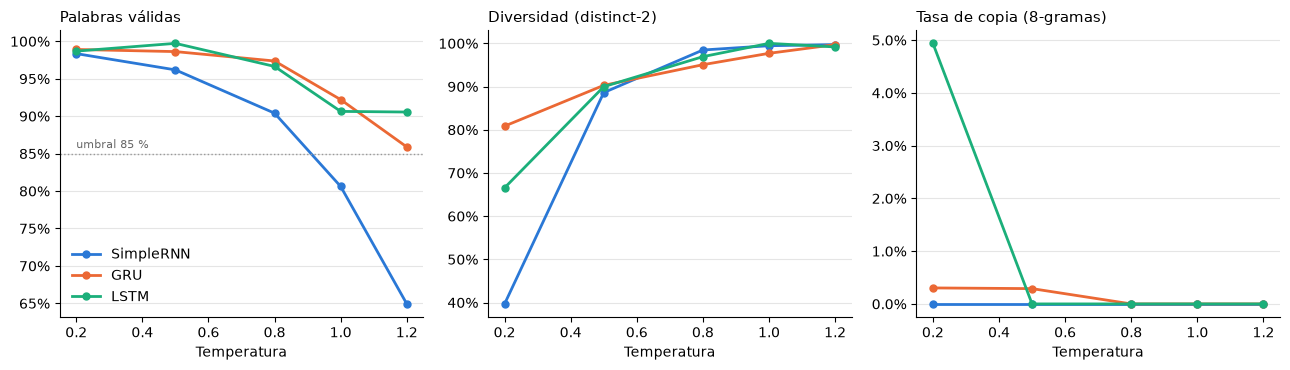

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True)
for ax, (columna, titulo) in zip(axes, [("palabras_validas", "Palabras válidas"),
                                        ("distinct_2", "Diversidad (distinct-2)"),
                                        ("tasa_copia", "Tasa de copia (8-gramas)")]):
    medias = df_eval.groupby(["modelo", "temperatura"])[columna].mean().unstack(0)
    for nombre in ["simplernn", "gru", "lstm"]:
        serie = medias[NOMBRES[nombre]]
        ax.plot(serie.index, serie.values, color=COLORES[nombre], linewidth=2, marker="o",
                markersize=5, label=NOMBRES[nombre])
    ax.set_title(titulo, loc="left", fontsize=11)
    ax.set_xlabel("Temperatura")
    decimales = 1 if columna == "tasa_copia" else 0
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _, d=decimales: f"{v:.{d}%}"))
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)
axes[0].axhline(0.85, color="#999999", linewidth=1, linestyle=":")
axes[0].annotate("umbral 85 %", (TEMPERATURAS[0], 0.85), xytext=(0, 4), textcoords="offset points",
                 fontsize=8, color="#666666")
axes[0].legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.savefig(DIR_SALIDAS / "metricas_generacion.png", dpi=150, bbox_inches="tight")
plt.show()

In [31]:
# Muestras del mejor modelo: 5 semillas × 5 temperaturas → outputs/muestras_generadas.md
lineas_md = [f"# Muestras generadas — modelo {NOMBRES[NOMBRE_MEJOR]}", "", f"> {LEYENDA}", ""]
for m in muestras_eval:
    lineas_md += [f"## Semilla: \"{m['semilla'].strip()}\" · T = {m['temperatura']}", "",
                  "```", m["texto"], "```", ""]
(DIR_SALIDAS / "muestras_generadas.md").write_text("\n".join(lineas_md), encoding="utf-8")

df_muestras = pd.DataFrame(muestras_eval)
df_muestras["texto"] = df_muestras["texto"].str.replace("\n", " ⏎ ")
print(f"{len(muestras_eval)} muestras guardadas en outputs/muestras_generadas.md\n{LEYENDA}")
df_muestras[df_muestras["temperatura"].isin([0.5, 0.8])]

25 muestras guardadas en outputs/muestras_generadas.md
[Texto generado automáticamente por un modelo con fines educativos. No representa declaraciones reales.]


,semilla,temperatura,texto
5,Buenos días a todas y a todos.,0.5,"Buenos días a todas y a todos. Hoy es una prueba de la mayor alimentación para poder decir. ⏎ Entonces, ahora no hay..."
6,El día de hoy vamos a informar sobre,0.5,"El día de hoy vamos a informar sobre el maíz de la carretera, pero no es que estamos muy comerciales, y esto es la c..."
7,La transformación de México,0.5,"La transformación de México y de la Comisión de México. ⏎ Entonces, estamos haciendo el gobierno de México de más de..."
8,"En materia de seguridad,",0.5,"En materia de seguridad, es muy bueno que todo lo que está diciendo que ""mañana está para el caso de los mecanismos,..."
9,Los programas del Bienestar,0.5,"Los programas del Bienestar y de la Comisión de México. ⏎ Entonces, estamos haciendo el gobierno de México de más de..."
10,Buenos días a todas y a todos.,0.8,"Buenos días a todas y a todos. Hoy es una prueba PISA aumentaron digamos, para muchos estudiantes para los jóvenes y..."
11,El día de hoy vamos a informar sobre,0.8,"El día de hoy vamos a informar sobre esta compañera. ⏎ Entonces, estamos viendo en el Pastelido de Educación y de Es..."
12,La transformación de México,0.8,"La transformación de México y 19 mil pesos. ⏎ Entonces, estamos viendo en el Pastelido de Educación y de Estados Uni..."
13,"En materia de seguridad,",0.8,"En materia de seguridad, eso fue la primera etalización y madre que participan una carretera hay dos boletas y a la ..."
14,Los programas del Bienestar,0.8,"Los programas del Bienestar y de la Comisión de Hacienda, Policía Mixitanciamiento en la otra de Gobierno Anteniendo..."


In [32]:
# Verificación de criterios de aceptación (SPECS §7.3)
fila_mejor = df_metricas.loc[NOMBRES[NOMBRE_MEJOR]]
validas_mejor = df_eval[(df_eval["modelo"] == NOMBRES[NOMBRE_MEJOR])
                        & df_eval["temperatura"].between(0.5, 0.8)]["palabras_validas"].mean()
mejor_con_compuertas = min(df_metricas.loc["GRU", "val_loss"], df_metricas.loc["LSTM", "val_loss"])
criterios = {
    "LSTM o GRU supera a SimpleRNN en val_loss": mejor_con_compuertas < df_metricas.loc["SimpleRNN", "val_loss"],
    f"BPC del modelo final ≤ 1.6 (obtenido: {fila_mejor['BPC']:.3f})": fila_mejor["BPC"] <= 1.6,
    f"≥ 85 % de palabras válidas con T = 0.5–0.8 (obtenido: {validas_mejor:.1%})": validas_mejor >= 0.85,
    "Entrenamiento en GPU": HAY_GPU,
}
for criterio_txt, cumple in criterios.items():
    print(f"{'✅' if cumple else '❌'} {criterio_txt}")

✅ LSTM o GRU supera a SimpleRNN en val_loss
❌ BPC del modelo final ≤ 1.6 (obtenido: 1.702)
✅ ≥ 85 % de palabras válidas con T = 0.5–0.8 (obtenido: 98.2%)
✅ Entrenamiento en GPU


### 11.1 Rúbrica cualitativa (calificación manual)

Lee las muestras de `outputs/muestras_generadas.md` (o las de arriba) y califica cada criterio de **1 (muy malo) a 5 (excelente)** para el mejor modelo. Edita esta celda para llenar la tabla (D-17).

| Criterio | T = 0.2 | T = 0.5 | T = 0.8 | T = 1.0 | T = 1.2 | Comentarios |
|---|---|---|---|---|---|---|
| Ortografía | | | | | | |
| Gramática local | | | | | | |
| Coherencia temática | | | | | | |
| Fidelidad al estilo | | | | | | |
| No repetición | | | | | | |
| **Promedio** | | | | | | |

## 12. Demo interactiva

Cambia `MODO_INTERACTIVO = True` en la sección 1 (o en la celda siguiente) y ejecuta la celda. Escribe una semilla, la longitud y la temperatura. Escribe `salir` para terminar.

In [33]:
# MODO_INTERACTIVO = True   # ← descomenta para habilitar la demo


def pedir_numero(mensaje, tipo, defecto, minimo, maximo):
    valor = input(f"{mensaje} [{defecto}]: ").strip()
    if not valor:
        return defecto
    try:
        valor = tipo(valor)
    except ValueError:
        print(f"Valor no válido, se usa {defecto}.")
        return defecto
    if not (minimo <= valor <= maximo):
        print(f"Fuera de rango ({minimo}–{maximo}), se usa {defecto}.")
        return defecto
    return valor


if MODO_INTERACTIVO:
    print(f"Modelo: {NOMBRES[NOMBRE_MEJOR]}. Escribe 'salir' para terminar.")
    while True:
        semilla_usuario = input("\nSemilla: ")
        if semilla_usuario.strip().lower() == "salir":
            break
        longitud = pedir_numero("Longitud", int, 500, 1, 5000)
        temperatura = pedir_numero("Temperatura", float, 0.7, 0.1, 2.0)
        print("\n" + generar_texto(modelo_final, semilla_usuario, longitud, temperatura, con_leyenda=True))
else:
    print("Demo interactiva deshabilitada (MODO_INTERACTIVO = False).")

Demo interactiva deshabilitada (MODO_INTERACTIVO = False).


### 12.1 Uso del modelo guardado sin reentrenar

Para generar texto en otra sesión basta con cargar el vocabulario, la configuración y los pesos. Para eso deben estar definidas la clase `ModeloCaracteres` y la función `generar_texto` (secciones 7 y 7.1).

In [34]:
with open(DIR_MODELOS / "config.json", encoding="utf-8") as f:
    config_cargada = json.load(f)
nombre_cargado = config_cargada["modelo_seleccionado"]
cfg = config_cargada["modelos"][nombre_cargado]
modelo_cargado = ModeloCaracteres(cfg["tipo_celda"], config_cargada["vocab_size"], EMB_DIM, cfg["unidades"],
                                  cfg["capas"], DROPOUT_ENTRADA, DROPOUT).to(DISPOSITIVO)
modelo_cargado.load_state_dict(torch.load(DIR_MODELOS / cfg["archivo"], map_location=DISPOSITIVO))
fijar_semillas()
print(generar_texto(modelo_cargado, "Muchas gracias. ", 300, 0.6, con_leyenda=True))

[Texto generado automáticamente por un modelo con fines educativos. No representa declaraciones reales.]
Muchas gracias. Vamos a dar el programa de Atención a las Causas, y el espacio de distintos lugares del diésel.
Y la garantía de la propia Universidad Transporte Fox el Recodo y el equipo de Seguridad.
Entonces, entre todo el proceso de recursos que había exportado el objetivo es la carretera y los centros de pesos


## 13. Conclusiones

La celda siguiente resume automáticamente los resultados de esta ejecución. El análisis escrito se completa en `INFORME.md`.

In [35]:
print(f"Modelo seleccionado: {NOMBRES[NOMBRE_MEJOR]}\n")
print(df_metricas[["Parámetros", "val_loss", "Perplejidad", "BPC", "Exactitud val", "Tiempo (min)"]].to_string())
print()
print(tabla_eval.xs(NOMBRES[NOMBRE_MEJOR], level="modelo").to_string())

Modelo seleccionado: LSTM

           Parámetros  val_loss  Perplejidad    BPC  Exactitud val  Tiempo (min)
Modelo                                                                          
SimpleRNN      131156    1.3589        3.892  1.961         0.6019          1.15
GRU           2615892    1.1957        3.306  1.725         0.6509          1.89
LSTM          3469908    1.1799        3.254  1.702         0.6529          1.81

             % palabras válidas  distinct-1  distinct-2  tasa de copia (8-gramas)
temperatura                                                                      
0.2                       0.987       0.395       0.666                     0.049
0.5                       0.997       0.596       0.900                     0.000
0.8                       0.966       0.729       0.969                     0.000
1.0                       0.906       0.830       1.000                     0.000
1.2                       0.906       0.773       0.992                    

### 13.1 Hallazgos

1. **Las compuertas importan.** La LSTM (val_loss ≈ 1.18, BPC ≈ 1.70, exactitud ≈ 65 %) y la GRU (≈ 1.20) superan claramente a la SimpleRNN (≈ 1.36, BPC ≈ 1.96): reducen la pérdida cerca de un 13 %. Con temperaturas altas, la proporción de palabras válidas de la SimpleRNN cae a ~81 % (T = 1.0) y ~65 % (T = 1.2), mientras que la LSTM y la GRU se mantienen en ≥ 86 %. Esto confirma empíricamente la teoría del gradiente que se desvanece (sección 6.2): la memoria aditiva de la LSTM y la GRU captura mejor el contexto.
2. **La LSTM es la mejor, pero por poco.** La GRU queda a solo ~1–2 % de la LSTM en `val_loss`, con 25 % menos parámetros. En un corpus pequeño, la diferencia entre ambas celdas es menor que la diferencia entre tener compuertas o no.
3. **El límite son los datos.** Los modelos con compuertas alcanzan su mejor validación en 7–10 épocas y luego sobreajustan: la pérdida de entrenamiento sigue bajando (≈ 0.97) mientras la de validación sube. El ajuste acotado (9.1) muestra que ni más dropout ni menos unidades bajan el piso de `val_loss` ≈ 1.17. La SimpleRNN, en cambio, nunca sobreajusta: su pérdida de validación es incluso menor que la de entrenamiento, porque el dropout solo actúa al entrenar. Su problema es la falta de capacidad (subajuste).
4. **El estilo se aprende bien.** El texto generado con T = 0.5–0.8 tiene ~97–99 % de palabras reales, usa correctamente `¿?`, comillas, mayúsculas al inicio de oración y nombres propios. Reproduce fórmulas características del discurso, como "Entonces," (aparece en 18 de las 25 muestras de evaluación), "el pueblo de México" o "la Secretaría de…". Esto ocurre sin que el modelo haya visto nunca el concepto de "palabra".
5. **La coherencia es solo local.** Las frases son gramaticalmente plausibles, pero el tema cambia cada una o dos oraciones. El modelo **inventa cifras y afirmaciones** con apariencia verosímil (p. ej. montos como "19 mil pesos" sin ningún sustento), lo que justifica el aviso de texto sintético (ADR-012).
6. **La temperatura controla el equilibrio entre creatividad y corrección.** Con T = 0.2 el texto es correcto pero repetitivo (distinct-2 de la LSTM ≈ 67 %, frente a ≈ 90–97 % con T = 0.5–0.8). Con T = 0.5–0.8 se logra el mejor equilibrio. Con T ≥ 1.0 aumenta la diversidad, pero aparecen palabras inventadas.
7. **No memoriza en el rango útil.** Con T ≥ 0.5 la tasa de copia de 8-gramas es prácticamente 0 %: el modelo recombina patrones en lugar de reproducir fragmentos del corpus. Solo con T = 0.2 la LSTM copia ≈ 5 % de sus 8-gramas, porque cae en las frases formulaicas más probables, que existen literalmente en el corpus.

### 13.2 Criterios de aceptación
Se cumplen tres de los cuatro criterios cuantitativos. El BPC del modelo final (≈ 1.70) **no alcanza el umbral de 1.6** que se fijó a priori en `SPECS.md`. Ese umbral era una estimación previa. Los experimentos de 9.1 indican que con este volumen de datos y esta partición de validación el piso práctico está en ≈ 1.69–1.70 BPC.

### 13.3 Aprendizajes
- La **preparación de datos** fue la etapa más laboriosa y la de mayor impacto. Separar hablantes, eliminar anotaciones y unificar tipografía redujo el vocabulario de 106 a 84 símbolos y dio un estilo homogéneo.
- La **validación por conferencias completas** da una métrica honesta pero exigente. Una división aleatoria de ventanas habría reportado una pérdida artificialmente baja por la fuga de información.
- El **early stopping** con checkpoint fue indispensable. Sin él, el modelo final habría sido el de la última época, que está sobreajustada.
- Entrenar en **GPU** (≈ 9 s por época para la LSTM frente a varios minutos en CPU) permitió comparar tres arquitecturas y cuatro variantes en menos de 20 minutos.

### 13.4 Limitaciones y trabajo futuro
- **Más datos:** incorporar más meses de conferencias es la mejora con mayor impacto esperado, dado que el modelo está limitado por los datos.
- **Tokenización por subpalabras** (BPE/SentencePiece) para dar más contexto semántico con la misma longitud de secuencia.
- **Mecanismos de atención o Transformers**, que capturan dependencias largas sin recurrencia y mejorarían la coherencia temática.
- **Condicionamiento por tema** (p. ej. un token de tema) para guiar la generación.